# New York City Property Price Forecast

## Project Goal

Explore property sales in New York City’s five boroughs from 2010 to 2025 and build a learning model that estimates possible house or apartment prices for the next five years.

The user can select a borough and property size. The model will forecast the median price per square foot and use it to estimate the property’s price.

## Data

Each row represents a recorded sale. The dataset includes the sale date, borough, address, sale price, building category, and `Gross Square Feet`.

Area is recorded in square feet. The dataset does not include the number of rooms, so that feature will not be used.

## Data Preparation

For each sale, calculate the price per square foot:

`price per square foot = sale price / area in square feet`

Exclude records with a missing or zero sale price or area. Review property categories separately because a building’s total area may not match the area of an individual apartment.

Then group sales by year and borough and calculate the median price per square foot and the number of sales. The median is less affected by unusually high or low sale prices.

## Model Training and Evaluation

The model will use borough and year. To evaluate its forecasts, train it on earlier years and compare its predictions with actual sales in later years. Do not randomly shuffle years, because the goal is to forecast the future.

This project does not use a baseline model.

## Forecast

After evaluation, train the model on historical data and forecast the next five years. Estimate the selected property’s price as follows:

`estimated property price = forecast price per square foot × property area`

Treat the result as an estimated range, not a guaranteed price. Uncertainty increases for years farther into the future.

In [3]:
import pandas as pd

file_path = "NYC_Property_Sales_2010_2025.xlsx"

book = pd.ExcelFile(file_path)
print(book.sheet_names)

df = pd.read_excel(file_path, sheet_name="2025")
print(df.shape)
print(df.columns.tolist())
df.head()

['2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
(85068, 23)
['Year', 'Borough', 'Borough Code', 'Neighborhood', 'Building Class Category', 'Tax Class at Present/Final Roll', 'Block', 'Lot', 'Easement', 'Building Class at Present/Final Roll', 'Address', 'Apartment Number', 'ZIP Code', 'Residential Units', 'Commercial Units', 'Total Units', 'Land Square Feet', 'Gross Square Feet', 'Year Built', 'Tax Class at Time of Sale', 'Building Class at Time of Sale', 'Sale Price', 'Sale Date']


,Year,Borough,Borough Code,Neighborhood,Building Class Category,Tax Class at Present/Final Roll,Block,Lot,Easement,Building Class at Present/Final Roll,...,Residential Units,Commercial Units,Total Units,Land Square Feet,Gross Square Feet,Year Built,Tax Class at Time of Sale,Building Class at Time of Sale,Sale Price,Sale Date
0,2025,Manhattan,1,ALPHABET CITY,01 ONE FAMILY DWELLINGS,1,376,43,NaN,S1,...,1.0,1.0,2.0,2090.0,3680.0,1940.0,1,S1,0,2025-01-23
1,2025,Manhattan,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,372,9,NaN,C7,...,8.0,1.0,9.0,2021.0,7129.0,1900.0,2,C7,0,2025-12-15
2,2025,Manhattan,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,372,19,NaN,C7,...,9.0,1.0,10.0,2401.0,6920.0,1920.0,2,C7,0,2025-02-07
3,2025,Manhattan,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,376,41,NaN,C6,...,28.0,0.0,28.0,4542.0,18254.0,1900.0,2,C4,540000,2025-12-17
4,2025,Manhattan,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,385,38,NaN,C6,...,20.0,2.0,22.0,3315.0,17160.0,1900.0,2,C4,0,2025-11-11


In [4]:
import pandas as pd

file_path = "NYC_Property_Sales_2010_2025.xlsx"

book = pd.ExcelFile(file_path)
print("Листы:", book.sheet_names)

df = pd.read_excel(file_path, sheet_name="2025")
print("Размер таблицы:", df.shape)
print("Колонки:", df.columns.tolist())

df.head()

Листы: ['2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
Размер таблицы: (85068, 23)
Колонки: ['Year', 'Borough', 'Borough Code', 'Neighborhood', 'Building Class Category', 'Tax Class at Present/Final Roll', 'Block', 'Lot', 'Easement', 'Building Class at Present/Final Roll', 'Address', 'Apartment Number', 'ZIP Code', 'Residential Units', 'Commercial Units', 'Total Units', 'Land Square Feet', 'Gross Square Feet', 'Year Built', 'Tax Class at Time of Sale', 'Building Class at Time of Sale', 'Sale Price', 'Sale Date']


,Year,Borough,Borough Code,Neighborhood,Building Class Category,Tax Class at Present/Final Roll,Block,Lot,Easement,Building Class at Present/Final Roll,...,Residential Units,Commercial Units,Total Units,Land Square Feet,Gross Square Feet,Year Built,Tax Class at Time of Sale,Building Class at Time of Sale,Sale Price,Sale Date
0,2025,Manhattan,1,ALPHABET CITY,01 ONE FAMILY DWELLINGS,1,376,43,NaN,S1,...,1.0,1.0,2.0,2090.0,3680.0,1940.0,1,S1,0,2025-01-23
1,2025,Manhattan,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,372,9,NaN,C7,...,8.0,1.0,9.0,2021.0,7129.0,1900.0,2,C7,0,2025-12-15
2,2025,Manhattan,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,372,19,NaN,C7,...,9.0,1.0,10.0,2401.0,6920.0,1920.0,2,C7,0,2025-02-07
3,2025,Manhattan,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,376,41,NaN,C6,...,28.0,0.0,28.0,4542.0,18254.0,1900.0,2,C4,540000,2025-12-17
4,2025,Manhattan,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,385,38,NaN,C6,...,20.0,2.0,22.0,3315.0,17160.0,1900.0,2,C4,0,2025-11-11


## 1. Inspect the Data

Before preparing the data, inspect the column types, summary statistics, and missing values. This helps identify which fields are available and which records may need special handling.

In [5]:
print("Column types:")
print(df.dtypes)

print("\nSummary:")
display(df[["Borough", "Sale Price", "Gross Square Feet", "Sale Date"]].describe(include="all"))

print("\nMissing values:")
missing = df.isna().sum()
display(missing[missing > 0].sort_values(ascending=False))

Column types:
Year                                             int64
Borough                                            str
Borough Code                                     int64
Neighborhood                                       str
Building Class Category                            str
Tax Class at Present/Final Roll                    str
Block                                            int64
Lot                                              int64
Easement                                       float64
Building Class at Present/Final Roll               str
Address                                            str
Apartment Number                                   str
ZIP Code                                       float64
Residential Units                              float64
Commercial Units                               float64
Total Units                                    float64
Land Square Feet                               float64
Gross Square Feet                              floa

,Borough,Sale Price,Gross Square Feet,Sale Date
count,85068,8.506800e+04,4.671000e+04,85068
unique,5,NaN,NaN,NaN
top,Queens,NaN,NaN,NaN
freq,27258,NaN,NaN,NaN
mean,NaN,2.059019e+06,5.043346e+03,2025-07-04 20:48:27.829031
min,NaN,0.000000e+00,0.000000e+00,2025-01-01 00:00:00
25%,NaN,0.000000e+00,1.392000e+03,2025-04-05 00:00:00
50%,NaN,4.990000e+05,1.987000e+03,2025-07-07 00:00:00
75%,NaN,1.055000e+06,2.820000e+03,2025-10-02 00:00:00
max,NaN,1.080000e+09,1.545708e+06,2025-12-31 00:00:00



Missing values:


Easement             85068
Apartment Number     64389
Land Square Feet     38360
Gross Square Feet    38358
Commercial Units     35207
Residential Units    20663
Total Units          17510
Year Built            5562
ZIP Code                19
dtype: int64

## 2. Check Property Categories

Before calculating price per square foot, inspect which property categories have both a positive sale price and a positive building area.

This is an initial data-quality check. For apartment records, `Gross Square Feet` may describe the whole building rather than an individual unit.

In [6]:
audit = df.assign(
    positive_price=df["Sale Price"].gt(0),
    positive_area=df["Gross Square Feet"].gt(0),
    usable_for_price_per_sqft=(
        df["Sale Price"].gt(0) & df["Gross Square Feet"].gt(0)
    )
)

category_summary = (
    audit.groupby("Building Class Category")
    .agg(
        records=("Sale Price", "size"),
        records_with_price=("positive_price", "sum"),
        records_with_area=("positive_area", "sum"),
        usable_records=("usable_for_price_per_sqft", "sum"),
    )
    .sort_values("usable_records", ascending=False)
)

display(category_summary.head(30))

,records,records_with_price,records_with_area,usable_records
Building Class Category,,,,
01 ONE FAMILY DWELLINGS,18578,10739,18408,10638
02 TWO FAMILY DWELLINGS,15732,7944,15718,7936
03 THREE FAMILY DWELLINGS,4522,2181,4518,2178
07 RENTALS - WALKUP APARTMENTS,2880,1705,2871,1698
22 STORE BUILDINGS,825,539,814,530
14 RENTALS - 4-10 UNIT,580,350,580,350
08 RENTALS - ELEVATOR APARTMENTS,432,286,432,286
21 OFFICE BUILDINGS,351,263,348,260
29 COMMERCIAL GARAGES,598,361,284,180


## 3. Calculate Price per Square Foot

Keep one- to three-family homes with a positive sale price and a positive building area. Calculate the sale price per square foot for each eligible record.

In [7]:
is_family_home = df["Building Class Category"].str.match(
    r"^\s*0[123]\b",
    na=False
)

has_valid_price_and_area = (
    df["Sale Price"].gt(0)
    & df["Gross Square Feet"].gt(0)
)

homes = df.loc[
    is_family_home & has_valid_price_and_area
].copy()

homes["Price per Sq Ft"] = (
    homes["Sale Price"] / homes["Gross Square Feet"]
)

print("Eligible home sales:", len(homes))
display(
    homes[
        [
            "Borough",
            "Address",
            "Building Class Category",
            "Sale Price",
            "Gross Square Feet",
            "Price per Sq Ft",
        ]
    ].head()
)

print("\nPrice per square foot summary:")
display(homes["Price per Sq Ft"].describe())

Eligible home sales: 20752


,Borough,Address,Building Class Category,Sale Price,Gross Square Feet,Price per Sq Ft
121,Manhattan,304 WEST 18TH STREET,01 ONE FAMILY DWELLINGS,4775000,3363.0,1419.863217
122,Manhattan,344 W 22 STREET,01 ONE FAMILY DWELLINGS,13100000,4395.0,2980.659841
123,Manhattan,348 WEST 22 STREET,01 ONE FAMILY DWELLINGS,13500000,3042.0,4437.869822
124,Manhattan,217 WEST 20 STREET,01 ONE FAMILY DWELLINGS,11600000,7805.0,1486.226778
125,Manhattan,204 WEST 21ST STREET,01 ONE FAMILY DWELLINGS,7650000,3365.0,2273.402675



Price per square foot summary:


count    20752.000000
mean       547.402574
std        377.978726
min          0.000185
25%        369.676797
50%        508.110101
75%        666.364170
max      10333.333333
Name: Price per Sq Ft, dtype: float64

In [8]:
columns_to_review = [
    "Borough",
    "Neighborhood",
    "Address",
    "Building Class Category",
    "Sale Price",
    "Gross Square Feet",
    "Price per Sq Ft",
    "Sale Date",
]

print("Lowest price per square foot:")
display(
    homes.nsmallest(10, "Price per Sq Ft")[columns_to_review]
)

print("Highest price per square foot:")
display(
    homes.nlargest(10, "Price per Sq Ft")[columns_to_review]
)

Lowest price per square foot:


,Borough,Neighborhood,Address,Building Class Category,Sale Price,Gross Square Feet,Price per Sq Ft,Sale Date
43739,Brooklyn,MILL BASIN,2278 EAST 64 STREET,01 ONE FAMILY DWELLINGS,1,5400.0,0.000185,2025-01-13
22088,Bronx,KINGSBRIDGE/JEROME PARK,2778 CLAFLIN AVENUE,03 THREE FAMILY DWELLINGS,1,4410.0,0.000227,2025-06-18
62527,Queens,FRESH MEADOWS,75-62 196 PLACE,01 ONE FAMILY DWELLINGS,1,4000.0,0.000250,2025-01-13
41167,Brooklyn,GRAVESEND,228 BAY 43 STREET,03 THREE FAMILY DWELLINGS,1,3972.0,0.000252,2025-07-06
5322,Manhattan,HARLEM-EAST,63 EAST 117 STREET,03 THREE FAMILY DWELLINGS,1,3864.0,0.000259,2025-10-03
35582,Brooklyn,CROWN HEIGHTS,1069 DEAN STREET,03 THREE FAMILY DWELLINGS,1,3840.0,0.000260,2025-02-21
41113,Brooklyn,GRAVESEND,8760 23 AVENUE,03 THREE FAMILY DWELLINGS,1,3654.0,0.000274,2025-04-21
73954,Queens,SOUTH JAMAICA,147-33 GLASSBORO AVENUE,02 TWO FAMILY DWELLINGS,1,3615.0,0.000277,2025-02-13
73956,Queens,SOUTH JAMAICA,147-29 GLASSBORO AVENUE,02 TWO FAMILY DWELLINGS,1,3615.0,0.000277,2025-02-13
73955,Queens,SOUTH JAMAICA,147-31 GLASSBORO AVENUE,02 TWO FAMILY DWELLINGS,1,3418.0,0.000293,2025-02-13


Highest price per square foot:


,Borough,Neighborhood,Address,Building Class Category,Sale Price,Gross Square Feet,Price per Sq Ft,Sale Date
44226,Brooklyn,OCEAN PARKWAY-NORTH,809 AVENUE J,01 ONE FAMILY DWELLINGS,15500000,1500.0,10333.333333,2025-10-06
45555,Brooklyn,PARK SLOPE,77 ST MARKS PLACE,03 THREE FAMILY DWELLINGS,24000000,2640.0,9090.909091,2025-09-18
30146,Brooklyn,BOERUM HILL,93 WYCKOFF STREET,02 TWO FAMILY DWELLINGS,6750000,1092.0,6181.318681,2025-05-15
29307,Brooklyn,BENSONHURST,1553 72 STREET,01 ONE FAMILY DWELLINGS,14250000,2403.0,5930.087391,2025-06-30
4051,Manhattan,GREENWICH VILLAGE-WEST,66 BEDFORD STREET,02 TWO FAMILY DWELLINGS,8000000,1398.0,5722.460658,2025-06-27
4032,Manhattan,GREENWICH VILLAGE-WEST,152 WEST 13 STREET,01 ONE FAMILY DWELLINGS,18750000,3381.0,5545.696539,2025-12-18
44871,Brooklyn,OCEAN PARKWAY-SOUTH,2085 EAST 3 STREET,01 ONE FAMILY DWELLINGS,7000000,1292.0,5417.956656,2025-07-15
78358,Staten Island,CLOVE LAKES,274 MORRISON AVENUE,01 ONE FAMILY DWELLINGS,725000,136.0,5330.882353,2025-07-29
4026,Manhattan,GREENWICH VILLAGE-WEST,11 ST. LUKE'S PLACE,01 ONE FAMILY DWELLINGS,24950000,4759.0,5242.698046,2025-01-22
44225,Brooklyn,OCEAN PARKWAY-NORTH,815 AVENUE J,01 ONE FAMILY DWELLINGS,15500000,3000.0,5166.666667,2025-10-06


## 4. Flag Nominal Sales

Some records have a positive sale price of only $1. This may represent a nominal transfer rather than a market sale, so it should not be used to estimate market prices.

In [9]:
homes["Is Nominal Sale"] = homes["Sale Price"].le(1)

print(
    "Sales priced at $1 or less:",
    homes["Is Nominal Sale"].sum()
)

homes_market = homes.loc[
    ~homes["Is Nominal Sale"]
].copy()

print("Remaining sales:", len(homes_market))

Sales priced at $1 or less: 181
Remaining sales: 20571


## 5. Review Small Building Areas

Check the smallest reported building areas for possible data errors before deciding whether to exclude them.

In [10]:
print("Building area distribution:")
display(
    homes_market["Gross Square Feet"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

columns_to_review = [
    "Borough",
    "Neighborhood",
    "Address",
    "Building Class Category",
    "Sale Price",
    "Gross Square Feet",
    "Price per Sq Ft",
    "Sale Date",
]

print("Ten smallest reported building areas:")
display(
    homes_market.nsmallest(10, "Gross Square Feet")[columns_to_review]
)

Building area distribution:


count    20571.000000
mean      1997.859900
std        948.356029
min        136.000000
1%         783.700000
5%         996.000000
25%       1350.000000
50%       1806.000000
75%       2400.000000
95%       3572.000000
99%       4840.000000
max      43504.000000
Name: Gross Square Feet, dtype: float64

Ten smallest reported building areas:


,Borough,Neighborhood,Address,Building Class Category,Sale Price,Gross Square Feet,Price per Sq Ft,Sale Date
78358,Staten Island,CLOVE LAKES,274 MORRISON AVENUE,01 ONE FAMILY DWELLINGS,725000,136.0,5330.882353,2025-07-29
79107,Staten Island,GRANT CITY,20 LIBERTY AVENUE,01 ONE FAMILY DWELLINGS,860000,220.0,3909.090909,2025-02-05
63428,Queens,HAMMELS,345 E BEACH 87 STREET,01 ONE FAMILY DWELLINGS,350000,300.0,1166.666667,2025-01-29
20661,Bronx,BRONXDALE,2912 LACONIA AVENUE,01 ONE FAMILY DWELLINGS,10,323.0,0.030960,2025-11-17
79660,Staten Island,GREAT KILLS,197 WIMAN AVENUE,01 ONE FAMILY DWELLINGS,425000,352.0,1207.386364,2025-06-27
83415,Staten Island,SOUTH BEACH,90 HICKORY AVENUE,01 ONE FAMILY DWELLINGS,525000,385.0,1363.636364,2025-10-27
50252,Queens,ASTORIA,21-62 49 STREET,01 ONE FAMILY DWELLINGS,810000,400.0,2025.000000,2025-10-08
74163,Queens,SOUTH OZONE PARK,134-07 116 AVENUE,01 ONE FAMILY DWELLINGS,435000,416.0,1045.673077,2025-11-21
80884,Staten Island,MIDLAND BEACH,566 HUNTER AVENUE,01 ONE FAMILY DWELLINGS,360000,420.0,857.142857,2025-09-02
80919,Staten Island,MIDLAND BEACH,665 HUNTER AVENUE,01 ONE FAMILY DWELLINGS,190000,420.0,452.380952,2025-10-17


In [11]:
print("Ten smallest areas:")
display(
    homes_market.nsmallest(10, "Gross Square Feet")[columns_to_review]
)

print("Ten largest areas:")
display(
    homes_market.nlargest(10, "Gross Square Feet")[columns_to_review]
)

Ten smallest areas:


,Borough,Neighborhood,Address,Building Class Category,Sale Price,Gross Square Feet,Price per Sq Ft,Sale Date
78358,Staten Island,CLOVE LAKES,274 MORRISON AVENUE,01 ONE FAMILY DWELLINGS,725000,136.0,5330.882353,2025-07-29
79107,Staten Island,GRANT CITY,20 LIBERTY AVENUE,01 ONE FAMILY DWELLINGS,860000,220.0,3909.090909,2025-02-05
63428,Queens,HAMMELS,345 E BEACH 87 STREET,01 ONE FAMILY DWELLINGS,350000,300.0,1166.666667,2025-01-29
20661,Bronx,BRONXDALE,2912 LACONIA AVENUE,01 ONE FAMILY DWELLINGS,10,323.0,0.030960,2025-11-17
79660,Staten Island,GREAT KILLS,197 WIMAN AVENUE,01 ONE FAMILY DWELLINGS,425000,352.0,1207.386364,2025-06-27
83415,Staten Island,SOUTH BEACH,90 HICKORY AVENUE,01 ONE FAMILY DWELLINGS,525000,385.0,1363.636364,2025-10-27
50252,Queens,ASTORIA,21-62 49 STREET,01 ONE FAMILY DWELLINGS,810000,400.0,2025.000000,2025-10-08
74163,Queens,SOUTH OZONE PARK,134-07 116 AVENUE,01 ONE FAMILY DWELLINGS,435000,416.0,1045.673077,2025-11-21
80884,Staten Island,MIDLAND BEACH,566 HUNTER AVENUE,01 ONE FAMILY DWELLINGS,360000,420.0,857.142857,2025-09-02
80919,Staten Island,MIDLAND BEACH,665 HUNTER AVENUE,01 ONE FAMILY DWELLINGS,190000,420.0,452.380952,2025-10-17


Ten largest areas:


,Borough,Neighborhood,Address,Building Class Category,Sale Price,Gross Square Feet,Price per Sq Ft,Sale Date
21414,Bronx,CROTONA PARK,1718 CROTONA PARK EAST,03 THREE FAMILY DWELLINGS,2325000,43504.0,53.443362,2025-06-16
76857,Queens,WOODSIDE,39-32 54TH STREET,02 TWO FAMILY DWELLINGS,1420000,19650.0,72.264631,2025-12-05
14003,Manhattan,UPPER EAST SIDE (79-96),4 EAST 80TH STREET,01 ONE FAMILY DWELLINGS,38000000,17676.0,2149.807649,2025-11-26
67404,Queens,LONG ISLAND CITY,45-40 PEARSON STREET,02 TWO FAMILY DWELLINGS,2293070,14684.0,156.161128,2025-12-05
11931,Manhattan,UPPER EAST SIDE (59-79),973 FIFTH AVENUE,01 ONE FAMILY DWELLINGS,46000000,13300.0,3458.646617,2025-05-21
11928,Manhattan,UPPER EAST SIDE (59-79),18 EAST 71 STREET,01 ONE FAMILY DWELLINGS,28000000,12060.0,2321.724710,2025-11-07
21585,Bronx,FIELDSTON,421 WEST 250 STREET,01 ONE FAMILY DWELLINGS,6500000,10800.0,601.851852,2025-01-07
80173,Staten Island,GRYMES HILL,160 BERTHA PLACE,01 ONE FAMILY DWELLINGS,3000000,10375.0,289.156627,2025-12-15
44881,Brooklyn,OCEAN PARKWAY-SOUTH,2174 EAST 4 STREET,01 ONE FAMILY DWELLINGS,7000000,10312.0,678.820791,2025-09-29
29429,Brooklyn,BENSONHURST,1744 70TH STREET,02 TWO FAMILY DWELLINGS,1065000,9728.0,109.477796,2025-09-22


## 6. Check Low Prices and Small Homes

A nonzero sale price can still be too low to represent a market sale. Very small reported building areas can also produce misleading prices per square foot.

Count and inspect these records before choosing data-cleaning rules.

In [12]:
low_price_count = homes_market["Sale Price"].lt(10_000).sum()
small_area_count = homes_market["Gross Square Feet"].lt(500).sum()

print("Sales below $10,000:", low_price_count)
print("Homes below 500 square feet:", small_area_count)

print("\nLowest recorded sale prices:")
display(
    homes_market.nsmallest(20, "Sale Price")[columns_to_review]
)

print("\nSmallest reported building areas:")
display(
    homes_market.nsmallest(20, "Gross Square Feet")[columns_to_review]
)

Sales below $10,000: 1038
Homes below 500 square feet: 29

Lowest recorded sale prices:


,Borough,Neighborhood,Address,Building Class Category,Sale Price,Gross Square Feet,Price per Sq Ft,Sale Date
19731,Bronx,BATHGATE,513 EAST 171 STREET,02 TWO FAMILY DWELLINGS,10,2400.0,0.004167,2025-10-14
19747,Bronx,BATHGATE,2064 BATHGATE AVENUE,02 TWO FAMILY DWELLINGS,10,2508.0,0.003987,2025-11-17
19820,Bronx,BAYCHESTER,3422 GUNTHER AVE,01 ONE FAMILY DWELLINGS,10,1714.0,0.005834,2025-01-30
19824,Bronx,BAYCHESTER,3320 WILSON AVENUE,01 ONE FAMILY DWELLINGS,10,2430.0,0.004115,2025-07-10
19868,Bronx,BAYCHESTER,3015 GRACE AVENUE,01 ONE FAMILY DWELLINGS,10,1260.0,0.007937,2025-05-14
19897,Bronx,BAYCHESTER,1174 EAST 224TH STREET,01 ONE FAMILY DWELLINGS,10,2052.0,0.004873,2025-10-28
19949,Bronx,BAYCHESTER,1138 214TH STREET,02 TWO FAMILY DWELLINGS,10,2018.0,0.004955,2025-03-12
19958,Bronx,BAYCHESTER,3637 FENTON AVENUE,02 TWO FAMILY DWELLINGS,10,2125.0,0.004706,2025-02-19
20030,Bronx,BAYCHESTER,3600 DE REIMER AVE,02 TWO FAMILY DWELLINGS,10,2070.0,0.004831,2025-11-06
20059,Bronx,BAYCHESTER,4053 WICKHAM AVENUE,02 TWO FAMILY DWELLINGS,10,1746.0,0.005727,2025-03-24



Smallest reported building areas:


,Borough,Neighborhood,Address,Building Class Category,Sale Price,Gross Square Feet,Price per Sq Ft,Sale Date
78358,Staten Island,CLOVE LAKES,274 MORRISON AVENUE,01 ONE FAMILY DWELLINGS,725000,136.0,5330.882353,2025-07-29
79107,Staten Island,GRANT CITY,20 LIBERTY AVENUE,01 ONE FAMILY DWELLINGS,860000,220.0,3909.090909,2025-02-05
63428,Queens,HAMMELS,345 E BEACH 87 STREET,01 ONE FAMILY DWELLINGS,350000,300.0,1166.666667,2025-01-29
20661,Bronx,BRONXDALE,2912 LACONIA AVENUE,01 ONE FAMILY DWELLINGS,10,323.0,0.030960,2025-11-17
79660,Staten Island,GREAT KILLS,197 WIMAN AVENUE,01 ONE FAMILY DWELLINGS,425000,352.0,1207.386364,2025-06-27
83415,Staten Island,SOUTH BEACH,90 HICKORY AVENUE,01 ONE FAMILY DWELLINGS,525000,385.0,1363.636364,2025-10-27
50252,Queens,ASTORIA,21-62 49 STREET,01 ONE FAMILY DWELLINGS,810000,400.0,2025.000000,2025-10-08
74163,Queens,SOUTH OZONE PARK,134-07 116 AVENUE,01 ONE FAMILY DWELLINGS,435000,416.0,1045.673077,2025-11-21
80884,Staten Island,MIDLAND BEACH,566 HUNTER AVENUE,01 ONE FAMILY DWELLINGS,360000,420.0,857.142857,2025-09-02
80919,Staten Island,MIDLAND BEACH,665 HUNTER AVENUE,01 ONE FAMILY DWELLINGS,190000,420.0,452.380952,2025-10-17


## 7. Create a Market-Sale Sample

Use $10,000 as a provisional minimum sale price. Keep homes under 500 square feet for now, but flag them so their effect can be reviewed before deciding whether to exclude them.

In [13]:
MIN_SALE_PRICE = 10_000
SMALL_AREA_LIMIT = 500

homes_for_model = homes_market.loc[
    homes_market["Sale Price"] >= MIN_SALE_PRICE
].copy()

homes_for_model["Small Area"] = (
    homes_for_model["Gross Square Feet"] < SMALL_AREA_LIMIT
)

print("Records after the minimum sale-price filter:", len(homes_for_model))
print("Records flagged for small area:", homes_for_model["Small Area"].sum())

display(
    homes_for_model.groupby("Small Area")["Price per Sq Ft"]
    .agg(["count", "median", "mean"])
)

Records after the minimum sale-price filter: 19533
Records flagged for small area: 28


,count,median,mean
Small Area,,,
False,19505,522.959184,580.582608
True,28,986.125470,1259.049055


## 8. Summarize 2025 Sales by Borough

Calculate the median sale price per square foot and the number of eligible sales for each borough.

In [14]:
homes_clean_2025 = homes_for_model.loc[
    ~homes_for_model["Small Area"]
].copy()

borough_summary_2025 = (
    homes_clean_2025.groupby("Borough")
    .agg(
        median_price_per_sqft=("Price per Sq Ft", "median"),
        sale_count=("Price per Sq Ft", "size"),
    )
    .reset_index()
    .sort_values("median_price_per_sqft", ascending=False)
)

display(borough_summary_2025)

,Borough,median_price_per_sqft,sale_count
2,Manhattan,1296.542553,237
1,Brooklyn,587.154912,5566
3,Queens,562.500000,7856
4,Staten Island,465.425532,3748
0,Bronx,375.477040,2098


## 9. Prepare Eligible Home Sales from All Years

Load the relevant columns from every yearly sheet. Keep one- to three-family homes with a positive price and positive area.

Flag low sale prices and small areas instead of deleting those rows. Create a separate filtered table for the model.

In [15]:
book = pd.ExcelFile(file_path)

columns_to_load = [
    "Borough",
    "Neighborhood",
    "Address",
    "Apartment Number",
    "Building Class Category",
    "Gross Square Feet",
    "Sale Price",
    "Sale Date",
]

parts = []

for sheet_name in book.sheet_names:
    year_data = book.parse(
        sheet_name=sheet_name,
        usecols=columns_to_load
    )

    is_family_home = year_data["Building Class Category"].str.match(
        r"^\s*0[123]\b",
        na=False
    )

    has_price_and_area = (
        year_data["Sale Price"].gt(0)
        & year_data["Gross Square Feet"].gt(0)
        & year_data["Sale Date"].notna()
    )

    eligible_rows = year_data.loc[
        is_family_home & has_price_and_area
    ].copy()

    eligible_rows["Sale Year"] = pd.to_datetime(
        eligible_rows["Sale Date"]
    ).dt.year

    eligible_rows["Price per Sq Ft"] = (
        eligible_rows["Sale Price"]
        / eligible_rows["Gross Square Feet"]
    )

    parts.append(eligible_rows)

sales_all = pd.concat(parts, ignore_index=True)

sales_all["Low Sale Price"] = sales_all["Sale Price"] < MIN_SALE_PRICE
sales_all["Small Area"] = (
    sales_all["Gross Square Feet"] < SMALL_AREA_LIMIT
)

sales_all["Use for Model"] = (
    ~sales_all["Low Sale Price"]
    & ~sales_all["Small Area"]
)

sales_model = sales_all.loc[
    sales_all["Use for Model"]
].copy()

print("Years:", sales_all["Sale Year"].min(), "to", sales_all["Sale Year"].max())
print("Eligible home records before price and area filters:", len(sales_all))
print("Low-price records flagged:", sales_all["Low Sale Price"].sum())
print("Small-area records flagged:", sales_all["Small Area"].sum())
print("Records kept for the model:", len(sales_model))

Years: 2010 to 2025
Eligible home records before price and area filters: 362366
Low-price records flagged: 14103
Small-area records flagged: 534
Records kept for the model: 347753


In [16]:
annual_borough = (
    sales_model.groupby(["Sale Year", "Borough"])
    .agg(
        median_price_per_sqft=("Price per Sq Ft", "median"),
        sale_count=("Price per Sq Ft", "size"),
    )
    .reset_index()
    .sort_values(["Sale Year", "Borough"])
)

print("Years:", annual_borough["Sale Year"].nunique())
print("Boroughs:", annual_borough["Borough"].nunique())
print("Year-borough groups:", len(annual_borough))

display(annual_borough.head(10))
display(annual_borough.tail(10))

Years: 16
Boroughs: 5
Year-borough groups: 80


,Sale Year,Borough,median_price_per_sqft,sale_count
0,2010,Bronx,177.033493,1697
1,2010,Brooklyn,239.414720,5326
2,2010,Manhattan,1000.501931,199
3,2010,Queens,251.479290,8819
4,2010,Staten Island,223.341794,3104
5,2011,Bronx,170.961048,1628
6,2011,Brooklyn,237.500000,5183
7,2011,Manhattan,976.482158,180
8,2011,Queens,249.208861,7694
9,2011,Staten Island,222.479452,2166


,Sale Year,Borough,median_price_per_sqft,sale_count
70,2024,Bronx,363.510554,2008
71,2024,Brooklyn,557.154605,5354
72,2024,Manhattan,1351.870835,211
73,2024,Queens,534.944667,7572
74,2024,Staten Island,443.181818,3696
75,2025,Bronx,375.477040,2098
76,2025,Brooklyn,587.154912,5566
77,2025,Manhattan,1296.542553,237
78,2025,Queens,562.500000,7856
79,2025,Staten Island,465.425532,3748


## 10. Visualize Historical Price Trends

Plot the annual median sale price per square foot for each borough. Use this chart to compare long-term trends and year-to-year changes.

Borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
Sale Year,,,,,
2010,177.03,239.41,1000.50,251.48,223.34
2011,170.96,237.50,976.48,249.21,222.48
2012,167.36,241.88,1032.38,261.74,222.74
2013,172.22,254.34,901.44,278.63,226.06
2014,175.51,286.18,1196.03,296.03,237.50
2015,194.94,346.62,1411.60,335.37,270.00
2016,200.90,370.37,1200.49,344.15,263.98
2017,236.26,417.49,1314.48,395.59,325.66
2018,254.63,444.11,1365.75,423.08,343.21


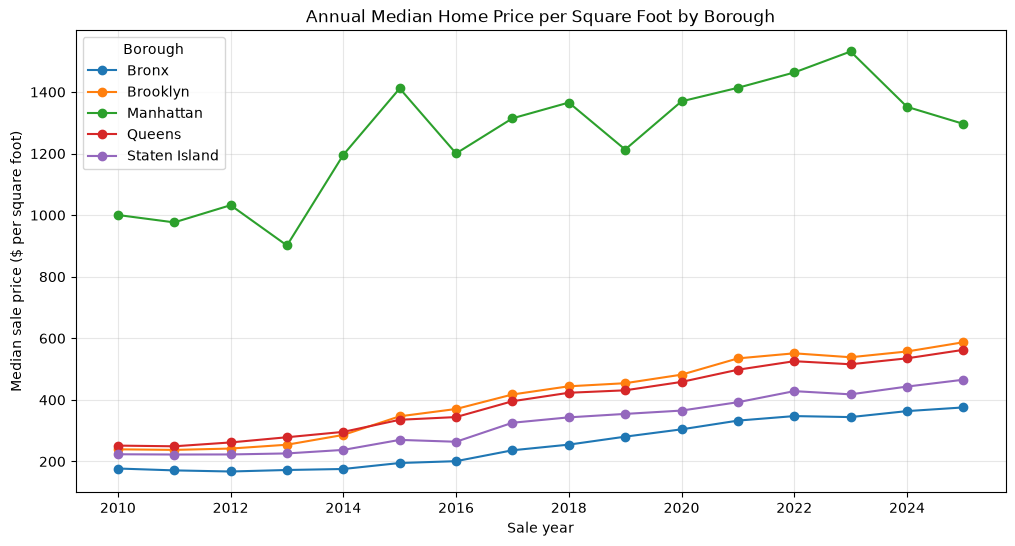

In [17]:
import matplotlib.pyplot as plt

price_trend = annual_borough.pivot(
    index="Sale Year",
    columns="Borough",
    values="median_price_per_sqft",
)

display(price_trend.round(2))

ax = price_trend.plot(
    figsize=(12, 6),
    marker="o",
)

ax.set_title("Annual Median Home Price per Square Foot by Borough")
ax.set_xlabel("Sale year")
ax.set_ylabel("Median sale price ($ per square foot)")
ax.grid(True, alpha=0.3)

plt.show()

## 11. Check Annual Sample Sizes

Review the number of eligible sales behind each borough-year median. Medians based on fewer sales may be less stable.

In [18]:
sales_count_trend = annual_borough.pivot(
    index="Sale Year",
    columns="Borough",
    values="sale_count",
)

display(sales_count_trend)

print("Minimum eligible sales in any borough-year group:")
display(sales_count_trend.min())

Borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
Sale Year,,,,,
2010,1697,5326,199,8819,3104
2011,1628,5183,180,7694,2166
2012,1636,5870,268,7914,2776
2013,1963,6984,262,8927,3514
2014,2175,7270,248,9124,3762
2015,2496,7284,236,9769,4275
2016,2865,7121,211,10028,4697
2017,3054,7006,207,10473,5171
2018,3129,6614,198,10221,5104


Minimum eligible sales in any borough-year group:


Borough
Bronx            1628
Brooklyn         4804
Manhattan         146
Queens           7301
Staten Island    2166
dtype: int64

## 12. Create a Time-Based Validation Split

Train the model on data from 2010–2022 and reserve 2023–2025 for validation. This simulates forecasting future years and prevents future data from leaking into training.

In [19]:
HOLDOUT_START_YEAR = 2023

train_panel = annual_borough.loc[
    annual_borough["Sale Year"] < HOLDOUT_START_YEAR
].copy()

test_panel = annual_borough.loc[
    annual_borough["Sale Year"] >= HOLDOUT_START_YEAR
].copy()

print(
    "Training years:",
    train_panel["Sale Year"].min(),
    "to",
    train_panel["Sale Year"].max(),
)
print("Training rows:", len(train_panel))

print(
    "Validation years:",
    test_panel["Sale Year"].min(),
    "to",
    test_panel["Sale Year"].max(),
)
print("Validation rows:", len(test_panel))

Training years: 2010 to 2022
Training rows: 65
Validation years: 2023 to 2025
Validation rows: 15


## 13. Train and Validate a Trend Model

Train a linear regression model on annual borough medians from 2010–2022. Include a separate time trend for each borough and evaluate the predictions on 2023–2025.

In [20]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

def make_features(frame):
    year_index = (frame["Sale Year"] - 2010).astype(float)

    borough_flags = pd.get_dummies(
        frame["Borough"],
        prefix="borough",
        drop_first=True,
        dtype=float,
    )

    year_interactions = borough_flags.mul(
        year_index,
        axis=0,
    ).add_prefix("year_x_")

    return pd.concat(
        [
            year_index.rename("year_index"),
            borough_flags,
            year_interactions,
        ],
        axis=1,
    )

X_train = make_features(train_panel)
X_test = make_features(test_panel).reindex(
    columns=X_train.columns,
    fill_value=0,
)

y_train_log = np.log(train_panel["median_price_per_sqft"])

model = LinearRegression()
model.fit(X_train, y_train_log)

predicted_price_per_sqft = np.exp(model.predict(X_test))
actual_price_per_sqft = test_panel["median_price_per_sqft"].to_numpy()

validation_results = test_panel[
    ["Sale Year", "Borough", "median_price_per_sqft", "sale_count"]
].copy()

validation_results["predicted_price_per_sqft"] = predicted_price_per_sqft

mae = mean_absolute_error(
    actual_price_per_sqft,
    predicted_price_per_sqft,
)

mape = (
    np.abs(
        (actual_price_per_sqft - predicted_price_per_sqft)
        / actual_price_per_sqft
    ).mean()
    * 100
)

print(f"Validation MAE: ${mae:,.2f} per square foot")
print(f"Validation MAPE: {mape:.1f}%")

display(validation_results.round(2))

Validation MAE: $88.38 per square foot
Validation MAPE: 12.4%


,Sale Year,Borough,median_price_per_sqft,sale_count,predicted_price_per_sqft
65,2023,Bronx,344.10,1963,357.49
66,2023,Brooklyn,538.46,5162,626.73
67,2023,Manhattan,1531.58,176,1539.02
68,2023,Queens,515.67,7301,567.81
69,2023,Staten Island,417.97,3622,442.79
70,2024,Bronx,363.51,2008,382.20
71,2024,Brooklyn,557.15,5354,679.16
72,2024,Manhattan,1351.87,211,1593.65
73,2024,Queens,534.94,7572,607.55
74,2024,Staten Island,443.18,3696,470.36


## 14. Diagnose Validation Errors

Compare prediction errors by borough and year. A positive error means the model overpredicted the observed median price per square foot.

In [21]:
validation_results["error"] = (
    validation_results["predicted_price_per_sqft"]
    - validation_results["median_price_per_sqft"]
)

validation_results["absolute_error"] = validation_results["error"].abs()

validation_results["absolute_pct_error"] = (
    validation_results["absolute_error"]
    / validation_results["median_price_per_sqft"]
    * 100
)

print("Error by borough:")
display(
    validation_results.groupby("Borough")
    .agg(
        mean_error=("error", "mean"),
        MAE=("absolute_error", "mean"),
        MAPE=("absolute_pct_error", "mean"),
    )
    .sort_values("MAPE", ascending=False)
    .round(1)
)

print("Error by year:")
display(
    validation_results.groupby("Sale Year")
    .agg(
        mean_error=("error", "mean"),
        MAE=("absolute_error", "mean"),
        MAPE=("absolute_pct_error", "mean"),
    )
    .round(1)
)

Error by borough:


,mean_error,MAE,MAPE
Borough,,,
Brooklyn,119.7,119.7,21.2
Manhattan,201.0,201.0,15.2
Queens,70.8,70.8,13.1
Staten Island,28.7,28.7,6.5
Bronx,21.7,21.7,6.0


Error by year:


,mean_error,MAE,MAPE
Sale Year,,,
2023,37.2,37.2,7.4
2024,96.5,96.5,12.9
2025,131.5,131.5,16.9


## 15. Compare a Recent-Years Trend

Fit a second model using only 2018–2022. Evaluate it on the same 2023–2025 validation data to see whether a more recent trend reduces forecast bias.

In [22]:
RECENT_START_YEAR = 2018

recent_train = train_panel.loc[
    train_panel["Sale Year"] >= RECENT_START_YEAR
].copy()

X_recent_train = make_features(recent_train)
X_recent_test = make_features(test_panel).reindex(
    columns=X_recent_train.columns,
    fill_value=0,
)

recent_model = LinearRegression()
recent_model.fit(
    X_recent_train,
    np.log(recent_train["median_price_per_sqft"]),
)

recent_predictions = np.exp(recent_model.predict(X_recent_test))

recent_mae = mean_absolute_error(
    test_panel["median_price_per_sqft"],
    recent_predictions,
)

recent_mape = (
    np.abs(
        (
            test_panel["median_price_per_sqft"].to_numpy()
            - recent_predictions
        )
        / test_panel["median_price_per_sqft"].to_numpy()
    ).mean()
    * 100
)

model_comparison = pd.DataFrame(
    {
        "Model": ["2010–2022 trend", "2018–2022 trend"],
        "Validation MAE": [mae, recent_mae],
        "Validation MAPE (%)": [mape, recent_mape],
    }
)

display(model_comparison.round(2))

,Model,Validation MAE,Validation MAPE (%)
0,2010–2022 trend,88.38,12.39
1,2018–2022 trend,72.07,10.73


## 16. Inspect Recent-Trend Predictions

Review the recent-years model's predictions and errors by borough and validation year. Positive errors mean overprediction; negative errors mean underprediction.

In [23]:
recent_validation = test_panel[
    ["Sale Year", "Borough", "median_price_per_sqft", "sale_count"]
].copy()

recent_validation["predicted_price_per_sqft"] = recent_predictions
recent_validation["error"] = (
    recent_validation["predicted_price_per_sqft"]
    - recent_validation["median_price_per_sqft"]
)
recent_validation["absolute_pct_error"] = (
    recent_validation["error"].abs()
    / recent_validation["median_price_per_sqft"]
    * 100
)

display(
    recent_validation[
        [
            "Sale Year",
            "Borough",
            "median_price_per_sqft",
            "predicted_price_per_sqft",
            "error",
            "absolute_pct_error",
        ]
    ].round(2)
)

,Sale Year,Borough,median_price_per_sqft,predicted_price_per_sqft,error,absolute_pct_error
65,2023,Bronx,344.10,382.92,38.82,11.28
66,2023,Brooklyn,538.46,587.50,49.04,9.11
67,2023,Manhattan,1531.58,1486.82,-44.76,2.92
68,2023,Queens,515.67,553.79,38.12,7.39
69,2023,Staten Island,417.97,442.24,24.27,5.81
70,2024,Bronx,363.51,414.46,50.95,14.02
71,2024,Brooklyn,557.15,623.55,66.39,11.92
72,2024,Manhattan,1351.87,1530.74,178.87,13.23
73,2024,Queens,534.94,586.76,51.82,9.69
74,2024,Staten Island,443.18,467.02,23.84,5.38


## 17. Review Error by Forecast Horizon

Measure validation error separately for each forecast horizon. Forecasts farther into the future may be less accurate than one-year-ahead forecasts.

In [24]:
recent_validation["forecast_horizon"] = (
    recent_validation["Sale Year"] - train_panel["Sale Year"].max()
)

error_by_horizon = (
    recent_validation.groupby("forecast_horizon")
    .agg(
        MAE=("error", lambda values: values.abs().mean()),
        MAPE=("absolute_pct_error", "mean"),
    )
    .reset_index()
)

display(error_by_horizon.round(2))

,forecast_horizon,MAE,MAPE
0,1,39.00,7.30
1,2,74.37,10.85
2,3,102.83,14.05


## 18. Backtest One- to Five-Year Forecasts

Repeat the forecast evaluation at several historical cutoffs. For each cutoff, train on the previous five years and evaluate predictions for the following five years.

In [25]:
backtest_rows = []

for cutoff_year in range(2015, 2021):
    training_window = annual_borough.loc[
        annual_borough["Sale Year"].between(cutoff_year - 4, cutoff_year)
    ].copy()

    future_window = annual_borough.loc[
        annual_borough["Sale Year"].between(cutoff_year + 1, cutoff_year + 5)
    ].copy()

    X_train_window = make_features(training_window)
    X_future_window = make_features(future_window).reindex(
        columns=X_train_window.columns,
        fill_value=0,
    )

    fold_model = LinearRegression()
    fold_model.fit(
        X_train_window,
        np.log(training_window["median_price_per_sqft"]),
    )

    fold_predictions = np.exp(
        fold_model.predict(X_future_window)
    )

    fold_results = future_window[
        ["Sale Year", "Borough", "median_price_per_sqft"]
    ].copy()

    fold_results["training_cutoff"] = cutoff_year
    fold_results["forecast_horizon"] = (
        fold_results["Sale Year"] - cutoff_year
    )
    fold_results["predicted_price_per_sqft"] = fold_predictions
    fold_results["error"] = (
        fold_results["predicted_price_per_sqft"]
        - fold_results["median_price_per_sqft"]
    )
    fold_results["absolute_pct_error"] = (
        fold_results["error"].abs()
        / fold_results["median_price_per_sqft"]
        * 100
    )

    backtest_rows.append(fold_results)

backtest = pd.concat(backtest_rows, ignore_index=True)

backtest_summary = (
    backtest.groupby("forecast_horizon")
    .agg(
        MAE=("error", lambda values: values.abs().mean()),
        MAPE=("absolute_pct_error", "mean"),
        mean_error=("error", "mean"),
        backtest_cases=("error", "size"),
    )
)

display(backtest_summary.round(2))

,MAE,MAPE,mean_error,backtest_cases
forecast_horizon,,,,
1,39.92,5.66,17.96,30
2,59.80,8.84,25.42,30
3,87.36,12.58,45.54,30
4,117.53,16.70,77.29,30
5,142.83,20.67,108.63,30


## 19. Compare Forecast Errors by Borough and Horizon

Compare mean absolute percentage error across boroughs at each forecast horizon. This shows whether some borough forecasts need wider uncertainty ranges.

In [26]:
mape_by_borough_horizon = backtest.pivot_table(
    index="forecast_horizon",
    columns="Borough",
    values="absolute_pct_error",
    aggfunc="mean",
)

display(mape_by_borough_horizon.round(1))

Borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
forecast_horizon,,,,,
1,3.9,5.2,10.4,3.0,5.8
2,7.7,8.3,14.1,5.0,9.1
3,12.1,13.2,19.1,6.6,11.9
4,17.4,18.6,24.4,9.1,13.9
5,22.3,25.5,25.5,12.8,17.3


## 20. Check the Direction of Backtest Errors

Mean absolute percentage error measures error size but not whether predictions were too high or too low. Calculate signed percentage error by borough and forecast horizon.

In [27]:
backtest["signed_pct_error"] = (
    (
        backtest["predicted_price_per_sqft"]
        - backtest["median_price_per_sqft"]
    )
    / backtest["median_price_per_sqft"]
    * 100
)

bias_by_borough_horizon = backtest.pivot_table(
    index="forecast_horizon",
    columns="Borough",
    values="signed_pct_error",
    aggfunc="mean",
)

display(bias_by_borough_horizon.round(1))

Borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
forecast_horizon,,,,,
1,-2.5,3.0,5.9,1.3,1.0
2,-3.8,6.3,7.7,1.9,0.3
3,-2.1,12.1,10.3,5.2,3.5
4,0.2,18.6,16.3,9.1,6.6
5,3.9,25.5,19.5,12.8,9.7


## 21. Forecast Prices per Square Foot

Fit the selected borough-specific trend model on the latest five years of data and forecast the median price per square foot for the next five years.

In [28]:
latest_year = int(annual_borough["Sale Year"].max())
training_start_year = latest_year - 4

final_training = annual_borough.loc[
    annual_borough["Sale Year"].between(training_start_year, latest_year)
].copy()

future_years = range(latest_year + 1, latest_year + 6)
boroughs = sorted(annual_borough["Borough"].unique())

future_panel = pd.MultiIndex.from_product(
    [future_years, boroughs],
    names=["Sale Year", "Borough"],
).to_frame(index=False)

X_final_train = make_features(final_training)
X_future = make_features(future_panel).reindex(
    columns=X_final_train.columns,
    fill_value=0,
)

final_model = LinearRegression()
final_model.fit(
    X_final_train,
    np.log(final_training["median_price_per_sqft"]),
)

future_panel["forecast_price_per_sqft"] = np.exp(
    final_model.predict(X_future)
)

forecast_table = future_panel.pivot(
    index="Sale Year",
    columns="Borough",
    values="forecast_price_per_sqft",
)

display(forecast_table.round(2))

Borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
Sale Year,,,,,
2026,384.05,587.26,1306.31,569.89,479.87
2027,395.25,598.99,1273.76,584.98,498.23
2028,406.79,610.96,1242.03,600.48,517.28
2029,418.66,623.16,1211.08,616.38,537.07
2030,430.88,635.60,1180.91,632.71,557.61


## 22. Estimate a Historical Forecast Range

Use the 10th and 90th percentiles of historical actual-to-predicted price ratios for each borough and forecast horizon. These approximate ranges are based on six backtest cases per group; they are not guaranteed prediction intervals.

In [29]:
backtest["actual_to_predicted_ratio"] = (
    backtest["median_price_per_sqft"]
    / backtest["predicted_price_per_sqft"]
)

ratio_ranges = (
    backtest.groupby(["forecast_horizon", "Borough"])[
        "actual_to_predicted_ratio"
    ]
    .quantile([0.10, 0.90])
    .unstack()
    .rename(columns={0.10: "lower_factor", 0.90: "upper_factor"})
    .reset_index()
)

forecast_with_range = future_panel.copy()
forecast_with_range["forecast_horizon"] = (
    forecast_with_range["Sale Year"] - latest_year
)

forecast_with_range = forecast_with_range.merge(
    ratio_ranges,
    on=["forecast_horizon", "Borough"],
)

forecast_with_range["lower_price_per_sqft"] = (
    forecast_with_range["forecast_price_per_sqft"]
    * forecast_with_range["lower_factor"]
)
forecast_with_range["upper_price_per_sqft"] = (
    forecast_with_range["forecast_price_per_sqft"]
    * forecast_with_range["upper_factor"]
)

selected_borough = "Queens"
property_area_sqft = 1500

property_forecast = forecast_with_range.loc[
    forecast_with_range["Borough"] == selected_borough
].copy()

property_forecast["estimated_price"] = (
    property_forecast["forecast_price_per_sqft"] * property_area_sqft
)
property_forecast["lower_estimated_price"] = (
    property_forecast["lower_price_per_sqft"] * property_area_sqft
)
property_forecast["upper_estimated_price"] = (
    property_forecast["upper_price_per_sqft"] * property_area_sqft
)

display(
    property_forecast[
        [
            "Sale Year",
            "Borough",
            "forecast_price_per_sqft",
            "lower_price_per_sqft",
            "upper_price_per_sqft",
            "estimated_price",
            "lower_estimated_price",
            "upper_estimated_price",
        ]
    ].round(0)
)

,Sale Year,Borough,forecast_price_per_sqft,lower_price_per_sqft,upper_price_per_sqft,estimated_price,lower_estimated_price,upper_estimated_price
3,2026,Queens,570.0,540.0,585.0,854834.0,810219.0,877812.0
8,2027,Queens,585.0,539.0,613.0,877476.0,808126.0,920153.0
13,2028,Queens,600.0,543.0,612.0,900718.0,814743.0,917322.0
18,2029,Queens,616.0,539.0,607.0,924575.0,808794.0,911226.0
23,2030,Queens,633.0,516.0,623.0,949065.0,774253.0,935020.0


In [37]:
area_sqft = 1500

all_borough_forecasts = forecast_with_range.copy()

all_borough_forecasts["estimated_price"] = (
    all_borough_forecasts["forecast_price_per_sqft"] * area_sqft
)
all_borough_forecasts["lower_estimated_price"] = (
    all_borough_forecasts["lower_price_per_sqft"] * area_sqft
)
all_borough_forecasts["upper_estimated_price"] = (
    all_borough_forecasts["upper_price_per_sqft"] * area_sqft
)

all_borough_forecasts = all_borough_forecasts.sort_values(
    ["Sale Year", "Borough"]
)

all_borough_forecasts[
    [
        "Sale Year",
        "Borough",
        "forecast_price_per_sqft",
        "lower_price_per_sqft",
        "upper_price_per_sqft",
        "estimated_price",
        "lower_estimated_price",
        "upper_estimated_price",
    ]
].round(2)

,Sale Year,Borough,forecast_price_per_sqft,lower_price_per_sqft,upper_price_per_sqft,estimated_price,lower_estimated_price,upper_estimated_price
0,2026,Bronx,384.05,376.31,415.38,576071.46,564468.15,623062.98
1,2026,Brooklyn,587.26,534.62,607.33,880896.38,801930.60,910992.05
2,2026,Manhattan,1306.31,1129.44,1403.02,1959462.61,1694155.07,2104536.67
3,2026,Queens,569.89,540.15,585.21,854834.35,810219.12,877812.28
4,2026,Staten Island,479.87,448.42,519.15,719810.52,672636.92,778721.38
5,2027,Bronx,395.25,375.20,462.13,592881.87,562807.42,693201.87
6,2027,Brooklyn,598.99,505.92,618.73,898489.11,758876.35,928101.82
7,2027,Manhattan,1273.76,1018.38,1414.47,1910643.11,1527565.26,2121701.93
8,2027,Queens,584.98,538.75,613.44,877476.38,808126.38,920152.71
9,2027,Staten Island,498.23,449.37,573.80,747341.25,674049.63,860702.21


In [38]:
forecast_with_range.to_csv("forecast_ranges.csv", index=False)